# Statistics and Data Analysis — Homework 1

### IDs
Insert your IDs in the cell below **and** in the header of `hw1.py`.

ID #1:

ID #2:

## Read the following instructions carefully

1. This notebook contains all the instructions. Your answers are the functions in **`hw1.py`** — complete them there.
   The notebook is for you: use it to develop, test, plot and explore (add as many cells as you like).
1. **Grading is fully automatic.** The grader imports your `hw1.py` and calls every function with **hidden inputs that are
   different from the default values**, and compares the results with the correct answers.
   Each function is tested on several hidden inputs and you get partial credit for every input that is answered correctly.
   Therefore:
   * Do **not** change the names of the functions or the names/order of their parameters. You may add parameters
     at the end, with default values.
   * Every function must **return** its answer in the exact type described in its docstring (printing is not enough).
   * Your functions must work for every valid input, not only for the defaults. Hard-coded answers get no credit.
   * Unless stated otherwise, answers must be exact up to floating point accuracy (relative error below $10^{-6}$).
     **No simulations** inside graded functions (simulations in the notebook, to check yourself, are encouraged!).
   * Every function must run in a **reasonable time** (seconds, not minutes) on a standard laptop. Calls that run too long are
     stopped and get no credit — write efficient code (see the size of the inputs mentioned in each question).
   * Do not run code at the top level of `hw1.py` (only imports and function definitions), do not call `input()`,
     and use only numpy, pandas, scipy, matplotlib and the Python standard library.
1. Write **efficient, vectorized** code whenever possible.
1. Before you submit, run the **self-check** cell at the end of this notebook. It verifies that your functions run and
   return the right types (not that they are correct).
1. Submit a **zip** file that contains `hw1.py` and this notebook, named with your IDs:
   `hw1_123456789_987654321.zip` (pairs) or `hw1_123456789.zip` (single).

In [220]:

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp

import hw1  # your solution file; thanks to autoreload, changes in hw1.py are picked up automatically

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## Question 1 — Is the new treatment better? (20 points)

Recall the kidney cancer example from class. Under the standard of care (SoC) the 5-year survival rate is $p_0 = 0.2$.
A new experimental treatment (Tx) was given to $n = 40$ patients and $16$ of them survived 5 years.
We test $H_0$: the survival rate under Tx is $p_0$, against the alternative that it is larger.

#### 1.A (4 points)
Complete `binom_pvalue(k, n, p0)`: the right-sided p-value $P(X \ge k)$ for $X \sim Binom(n, p_0)$.

For the default values you should get the result from class, $\approx 0.002936$.

In [178]:
hw1.binom_pvalue()

np.float64(0.002936197349630243)

In [179]:
# Sanity check Cell
hw1.binom_pvalue(k=4, n=100, p0=0.1)

np.float64(0.9921635128788155)

#### 1.B (4 points)
Before running a trial we fix a significance level $\alpha$ and decide to declare Tx better if $X \ge k^*$, where
$k^*$ is the **smallest** $k$ whose p-value $P(X \ge k)$ is at most $\alpha$.

Complete `critical_k(n, p0, alpha)` that returns $k^*$ (if no $k \in \{0,\dots,n\}$ qualifies, return $n+1$).

In [180]:
# Sanity check Cell

pvalue = hw1.binom_pvalue(k=15, n=40, p0=0.2)
alpha = 0.01
if pvalue <= alpha:
    print("YAY")
else:
    print("oh no !")

hw1.critical_k()

YAY


15

In [181]:
hw1.critical_k()

15

#### Power: can the study detect a real improvement?

The rule of 1.B controls **false alarms**: if Tx is no better than SoC ($p = p_0$), the probability that we declare Tx better
($X \ge k^*$) is at most $\alpha$. But a study must also be able to **detect a real improvement**.

Suppose that the true 5-year survival rate under Tx is $p_1 > p_0$. Then $X \sim Binom(n, p_1)$, and the probability that the study
declares Tx better is called the **power** of the study:

$$\text{power}(n) = P(X \ge k^*) \quad\text{where } X \sim Binom(n, p_1) \text{ and } k^* = \texttt{critical\_k}(n, p_0, \alpha).$$

Note the two different probabilities: the threshold $k^*$ is computed under $p_0$ (when we plan the study we do not know $p_1$),
but the power is computed under $p_1$. $1 - \text{power}$ is the probability that we **miss** a real improvement.

**Example.** With $n = 40$, $p_0 = 0.2$ and $\alpha = 0.01$ we get $k^* = 15$. If the true survival rate under Tx is $p_1 = 0.35$,
the power is $P(Binom(40, 0.35) \ge 15) \approx 0.43$: such a study would *miss* a real improvement from 20% to 35% survival
more often than it would detect it!

#### 1.C (4 points)
Complete `power(n, p0, p1, alpha)`. For the default values you should get $\approx 0.4279$ (the example above).

In [182]:
hw1.power()

np.float64(0.42791785216470135)

In [183]:
hw1.power(n=5, p0=0.5, p1=0.9, alpha=0.01)

np.float64(0.0)

#### 1.D (4 points)
Does adding a patient always increase the power? Complete `power_drops(p0, p1, alpha, n_max)` that returns, as a sorted 1-d
numpy array of ints, every $n \in \{2, \dots, n_{max}\}$ for which the power with $n$ patients is **smaller** than the power
with $n - 1$ patients.

In [184]:
hw1.power_drops()

array([  4,   6,   8,  11,  14,  17,  21,  24,  27,  31,  34,  38,  41,
        45,  49,  53,  56,  60,  64,  68,  72,  76,  80,  84,  88,  92,
        96, 100, 104, 108, 112, 116, 120, 124, 128, 133, 137, 141, 145,
       149])

#### 1.E (4 points)
How many patients do we need? Complete `min_sample_size(p0, p1, alpha, target)` that returns the **smallest** $n \ge 1$
for which the power is at least `target`.

In [185]:
hw1.min_sample_size()
# N around 65k
hw1.min_sample_size(p0=0.2, p1=0.205, alpha=0.01, target=0.8)

64761

---
## Question 2 — Randomistan basketball: who finishes first? (18 points)

A player shoots free throws; each shot succeeds with probability $p$, independently of all other shots.
Let $T$ be the number of shots the player takes until their $r$-th success (so $T \in \{r, r+1, \dots\}$).

> Note: `scipy.stats.nbinom` counts something slightly different. Read its documentation.

#### 2.A (6 points)
Complete `shots_pmf(t, r, p)` that returns $P(T = t)$. The argument `t` may be a single integer (return a float)
or a 1-d numpy array of integers (return an array of the same length).

In [186]:
print(hw1.shots_pmf())
print(hw1.shots_pmf(np.arange(0, 8)))

0.06449725440000002
[0.       0.       0.       0.064    0.1152   0.13824  0.13824  0.124416]


#### 2.B (6 points)
Two players, A and B, shoot **synchronously**: in every round each of them takes one shot. All shots are independent.
Player A needs $r_A$ successes and succeeds with probability $p_A$; player B needs $r_B$ successes and succeeds with probability $p_B$.

Complete `duel_probs(pA, rA, pB, rB)` that returns the tuple
$\big(P(T_A < T_B),\ P(T_A = T_B),\ P(T_A > T_B)\big)$.

In [187]:
hw1.duel_probs()

(np.float64(0.5539953717288117),
 np.float64(0.05227650982454465),
 np.float64(0.3937281184466348))

#### 2.C (6 points)
Complete `duel_expected_length(pA, rA, pB, rB)` that returns $E[\min(T_A, T_B)]$, the expected number of rounds until the
first of the two players completes their task.

*Hint:* for a random variable $M$ with values in $\{0, 1, 2, \dots\}$, $E[M] = \sum_{t \ge 0} P(M > t)$.

In [188]:
hw1.duel_expected_length()

np.float64(14.129634529538725)

---
## Question 3 — Sums of independent random variables (17 points)

A distribution of a random variable with finitely many **integer** values is represented by a 2-d numpy array
`[[values], [probabilities]]`, e.g. a fair die is `np.array([[1, 2, 3, 4, 5, 6], [1/6]*6])`.
The values are integers, but they are not necessarily sorted, consecutive, small, or positive.

#### 3.A (8 points)
Complete `conv_pmf(P, Q)` that returns the distribution of $X + Y$, where $X \sim P$ and $Y \sim Q$ are independent,
in the same representation, with the values sorted in increasing order.

In [255]:
die = np.array([[1, 2, 3, 4, 5, 6], [1 / 6] * 6])
X = die
Y = die
sums = (X[0, :, None] + Y[0, None, :]).ravel()
sums = sums.astype(int)
values = np.unique(sums, return_inverse=True)[0]
total_events_count_X = len(X[0])
total_events_count_Y = len(Y[0])
total_events_count_Z = len(values)
probabilities = []

for z in range(total_events_count_Z):
    p_Z_at_z = 0
    for i in range(total_events_count_X):
        for j in range(total_events_count_Y):
            if X[0][i] + Y[0][j] == values[z]:
                p_Z_at_z += X[1][i] * Y[1][j]
    p_Z_at_z = float(p_Z_at_z)
    probabilities.append(p_Z_at_z)

if not np.isclose(np.sum(probabilities), 1):
    print("Problem !")

order = np.argsort(values)
values = values[order]
probabilities = np.array(probabilities)[order]
Z = np.asarray([values, probabilities])

print(Z)

[[ 2.          3.          4.          5.          6.          7.
   8.          9.         10.         11.         12.        ]
 [ 0.02777778  0.05555556  0.08333333  0.11111111  0.13888889  0.16666667
   0.13888889  0.11111111  0.08333333  0.05555556  0.02777778]]


In [256]:
die = np.array([[1, 2, 3, 4, 5, 6], [1 / 6] * 6])

hw1.conv_pmf(die, die)

array([[ 2.        ,  3.        ,  4.        ,  5.        ,  6.        ,
         7.        ,  8.        ,  9.        , 10.        , 11.        ,
        12.        ],
       [ 0.02777778,  0.05555556,  0.08333333,  0.11111111,  0.13888889,
         0.16666667,  0.13888889,  0.11111111,  0.08333333,  0.05555556,
         0.02777778]])

#### 3.B (9 points)
Complete `nfold_pmf(P, n)` that returns the distribution of $X_1 + \dots + X_n$ where $X_1, \dots, X_n$ are independent
and each has the distribution $P$.

Your function will be tested with $n$ up to $2000$ and with supports such as $\{0, 1000, 2500\}$ — it must be efficient.

In [261]:
P = die
n = 2

values_X = P[0].astype(int)
probabilities_X = P[1]

if len(np.unique(values_X)) == 1:
    Z = np.array([[n * values_X[0]], [1.0]])
else:
    smallest_value = values_X.min()
    shifted_values = values_X - smallest_value

    step = np.gcd.reduce(shifted_values)
    grid_values = shifted_values // step

    probabilities_on_grid = np.zeros(grid_values.max() + 1)
    for i in range(len(grid_values)):
        probabilities_on_grid[grid_values[i]] += probabilities_X[i]


    probabilities_of_sum = np.array([1.0])
    for k in range(n):
        probabilities_of_sum = np.convolve(probabilities_of_sum, probabilities_on_grid)

    grid_sums = np.arange(len(probabilities_of_sum))
    values_of_sum = n * smallest_value + step * grid_sums

    possible = probabilities_of_sum > 0
    values_of_sum = values_of_sum[possible]
    probabilities_of_sum = probabilities_of_sum[possible]

    General_Z = np.array([values_of_sum, probabilities_of_sum])

print(Z)

[[ 2.          3.          4.          5.          6.          7.
   8.          9.         10.         11.         12.        ]
 [ 0.02777778  0.05555556  0.08333333  0.11111111  0.13888889  0.16666667
   0.13888889  0.11111111  0.08333333  0.05555556  0.02777778]]


In [259]:
hw1.nfold_pmf(die, 3)

array([[3.00000000e+00, 4.00000000e+00, 5.00000000e+00, 6.00000000e+00,
        7.00000000e+00, 8.00000000e+00, 9.00000000e+00, 1.00000000e+01,
        1.10000000e+01, 1.20000000e+01, 1.30000000e+01, 1.40000000e+01,
        1.50000000e+01, 1.60000000e+01, 1.70000000e+01, 1.80000000e+01],
       [4.62962963e-03, 1.38888889e-02, 2.77777778e-02, 4.62962963e-02,
        6.94444444e-02, 9.72222222e-02, 1.15740741e-01, 1.25000000e-01,
        1.25000000e-01, 1.15740741e-01, 9.72222222e-02, 6.94444444e-02,
        4.62962963e-02, 2.77777778e-02, 1.38888889e-02, 4.62962963e-03]])

---
## Question 4 — Collecting coupons (17 points)

In every draw we get one of $N$ equiprobable coupons, independently of all previous draws.
Let $T_N$ be the number of draws until we have seen all $N$ coupons.

#### 4.A (8 points)
Complete `cc_cdf(N, t)` that returns $P(T_N \le t)$ **exactly** (no simulation).

Use the exact method from class (Lecture 3: $T_N$ as a sum of independent geometric waiting times).
Your function must keep a **relative** error below $10^{-6}$ for $N \le 300$ and $t \le 3000$, even when the probability is
tiny (e.g. $10^{-12}$) — closed-form formulas you may find elsewhere are not always numerically safe.

In [ ]:
hw1.cc_cdf()

#### 4.B (9 points)
Often we do not need the full collection. Complete `cc_partial_quantile(N, m, q)` that returns the smallest number of draws
$t$ such that, with probability at least $q$, at least $m$ different coupons appear among the first $t$ draws.

In [ ]:
hw1.cc_partial_quantile()

---
## Question 5 — Auditing the factory inspection logs (28 points)

The Randomistan factory has four production machines: **A, B, C and D**. Products are inspected in batches.
Every batch is inspected once, and the inspection system writes one line per batch to a log file with the columns

| column | meaning |
|---|---|
| `log_line` | line number in the log file |
| `batch_id` | identifier of the batch (every batch has a different id) |
| `timestamp` | time of the inspection |
| `machine` | the machine that produced the batch |
| `sensor_fw` | firmware version of the inspection sensor (sensors are upgraded from time to time) |
| `inspected` | number of products inspected in the batch |
| `defective` | number of defective products found in the batch |

The manufacturer of the machines claims that their defect rate is at most 3%. You are hired to audit the claim.

**Real logs are messy.** The inspection system has several kinds of recording problems, and they show up in the logs
(every log contains each kind, in different machines, at different times and to different extents).

You get three logs to explore: `factory_log_1.csv`, `factory_log_2.csv`, `factory_log_3.csv`.
Your functions will be graded on **other logs from the same system** that you do not have. They must therefore detect and
handle the problems **automatically** — do not hard-code dates, line numbers, batch ids or machines.

A batch is **usable** if its true number of defective products can be determined from the log
(possibly after correcting how it was recorded). Your analysis must use **every usable batch exactly once, with its true values,
and nothing else**.

We also give you `factory_log_clean.csv`: a log of the same system **without** recording problems. Use it to check
5.B–5.D independently of your cleaning (the expected results are given below). Your functions will also be tested on clean logs,
so make sure that your cleaning does not damage a clean log.

**Explore before you compute.**

In [194]:
logs = {i: pd.read_csv(f'factory_log_{i}.csv') for i in [1, 2, 3]}
clean = pd.read_csv('factory_log_clean.csv')
logs[1].head()

,log_line,batch_id,timestamp,machine,sensor_fw,inspected,defective
0,1,100001,2026-01-01 10:31:43,C,2.3.0,691,46
1,2,100003,2026-01-01 12:42:33,B,2.3.0,566,20
2,3,100005,2026-01-01 13:12:09,C,2.3.0,410,28
3,4,100008,2026-01-01 18:08:13,D,2.2.1,674,16
4,5,100011,2026-01-02 00:26:08,B,2.3.0,428,22


#### 5.A (10 points)
Complete `clean_log(df)`: it receives a raw log (a DataFrame, as returned by `pd.read_csv`) and returns a DataFrame with
**one row per usable batch** and the columns `batch_id, machine, inspected, defective` holding the **true** values
(machine names exactly `'A'`, `'B'`, `'C'`, `'D'`).

Grading: for every hidden log we check the fraction of affected batches that you handled correctly;
batches without problems that you dropped or changed cost points.

In [195]:
before_cleaning_logs = {i: pd.read_csv(f'factory_log_{i}.csv') for i in [1, 2, 3]}
experimental_logs = before_cleaning_logs
df = experimental_logs[1]

print(df.count())
print(df.describe())

log_line     2686
batch_id     2686
timestamp    2686
machine      2686
sensor_fw    2686
inspected    2686
defective    2686
dtype: int64
          log_line       batch_id    inspected    defective
count  2686.000000    2686.000000  2686.000000  2686.000000
mean   1343.500000  102708.579672   498.689873    26.104989
std     775.525736    1567.423756   114.033623    12.166174
min       1.000000  100001.000000   300.000000    -1.000000
25%     672.250000  101349.500000   400.000000    18.000000
50%    1343.500000  102702.500000   498.000000    24.000000
75%    2014.750000  104061.250000   595.000000    33.000000
max    2686.000000  105421.000000   700.000000    96.000000


In [196]:
# Handle names
## Correct those that are recording errors
df['machine'] = df['machine'].str.strip().str.upper()

# Keep only the ones that look exactly like that
valid_names = ['A', 'B', 'C', 'D']
df = df.loc[df['machine'].isin(valid_names)]

# Remove any inspection that has negative values or more than the products that inputted for the machine
df = df.loc[(df['defective'] >= 0) & (df['defective'] <= df['inspected'])]


In [197]:
# Check for exactly identical rows
rows_before = df["log_line"].count()
df = df.drop_duplicates(subset=[c for c in df.columns if c != "log_line"], keep="first")
print(f"Removed {rows_before - df.count()} Identical Duplicates of rows")

# Check if there are batch_ids that appeared more than once, if thats true, make sure it's not a recording problem
rows_before = df["log_line"].count()
df = df.drop_duplicates(subset=["batch_id", "machine", "sensor_fw", "inspected", "defective"], keep="first")
print(f"Removed {rows_before - df["log_line"].count()} lines of duplicated batch_ids")

# Check if there are timestamps that appeared more than once, if thats true, make sure it's not a recording problem
rows_before = df["log_line"].count()
df = df.drop_duplicates(subset=["timestamp", "machine", "sensor_fw", "inspected", "defective"], keep="first")
print(f"Removed {rows_before - df["log_line"].count()} lines of duplicated timestamps")


Removed log_line     0
batch_id     0
timestamp    0
machine      0
sensor_fw    0
inspected    0
defective    0
dtype: int64 Identical Duplicates of rows
Removed 0 lines of duplicated batch_ids
Removed 82 lines of duplicated timestamps


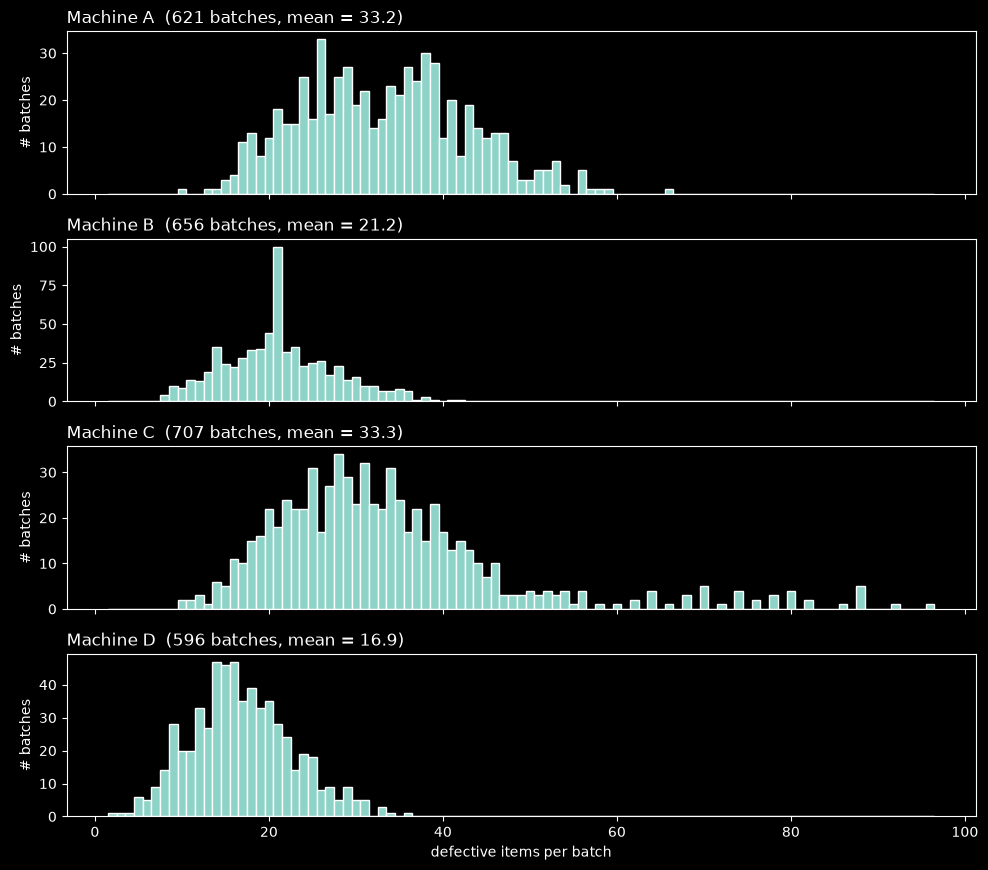

In [198]:
df = df.drop_duplicates(subset=[c for c in df.columns if c != "log_line"], keep="first")
machines = sorted(df["machine"].unique())
bins = np.arange(df["defective"].min(), df["defective"].max() + 2) - 0.5  # one bar per integer

fig, axes = plt.subplots(len(machines), 1, figsize=(10, 2.2 * len(machines)), sharex=True)

for ax, machine in zip(axes, machines):
    defective = df.loc[df["machine"] == machine, "defective"]
    ax.hist(defective, bins=bins, edgecolor="white")
    ax.set_title(f"Machine {machine}  ({len(defective)} batches, mean = {defective.mean():.1f})", loc="left")
    ax.set_ylabel("# batches")

axes[-1].set_xlabel("defective items per batch")
fig.tight_layout()
plt.show()

In [199]:
groups = df.groupby('machine')

potential_fault_sensor_by_batch_id = {}
total_potential_faulted_inspections = {}

for machine_name, machine_rows in groups:
    # Strating with machine X
    # Compare upcoming values if they are different to the starting value
    same_result_batch_id = (machine_rows['defective'] != machine_rows['defective'].shift()).cumsum()

    step_a = machine_rows.assign(same_result_batch_id=same_result_batch_id).reset_index()
    step_b = step_a.groupby("same_result_batch_id")

    step_c = step_b.agg(value=("defective", "first"),
                        start_index=("index", "first"),
                        last_index=("index", "last"),
                        times_appeared=("defective", "size"))

    potential_fault_sensor_by_batch_id[machine_name] = step_c[step_c["times_appeared"] > 1]
    total_potential_faulted_inspections[machine_name] = potential_fault_sensor_by_batch_id[machine_name][
        "times_appeared"].sum()


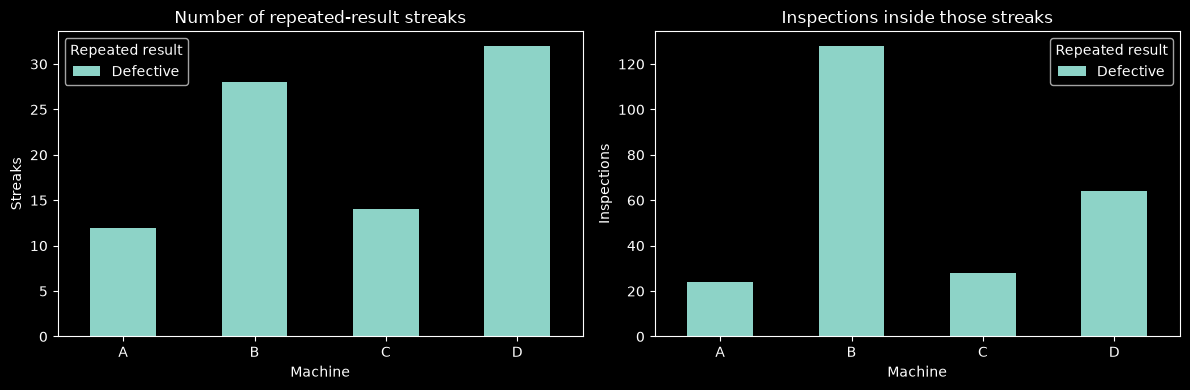

In [200]:
streaks = (
    pd.concat(potential_fault_sensor_by_batch_id, names=["machine", "same_result_batch_id"])
    .reset_index()
)
streaks["stuck_on"] = streaks["value"].astype(bool).map({True: "Defective", False: "Not defective"})

# How many streaks per machine, split by which result repeated
counts = streaks.pivot_table(index="machine", columns="stuck_on",
                             values="times_appeared", aggfunc="size", fill_value=0)

# How many inspections those streaks cover, split the same way
inspections = streaks.pivot_table(index="machine", columns="stuck_on",
                                  values="times_appeared", aggfunc="sum", fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

counts.plot.bar(ax=axes[0])
axes[0].set_title("Number of repeated-result streaks")
axes[0].set_ylabel("Streaks")

inspections.plot.bar(ax=axes[1])
axes[1].set_title("Inspections inside those streaks")
axes[1].set_ylabel("Inspections")

for ax in axes:
    ax.set_xlabel("Machine")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Repeated result")

plt.tight_layout()
plt.show()

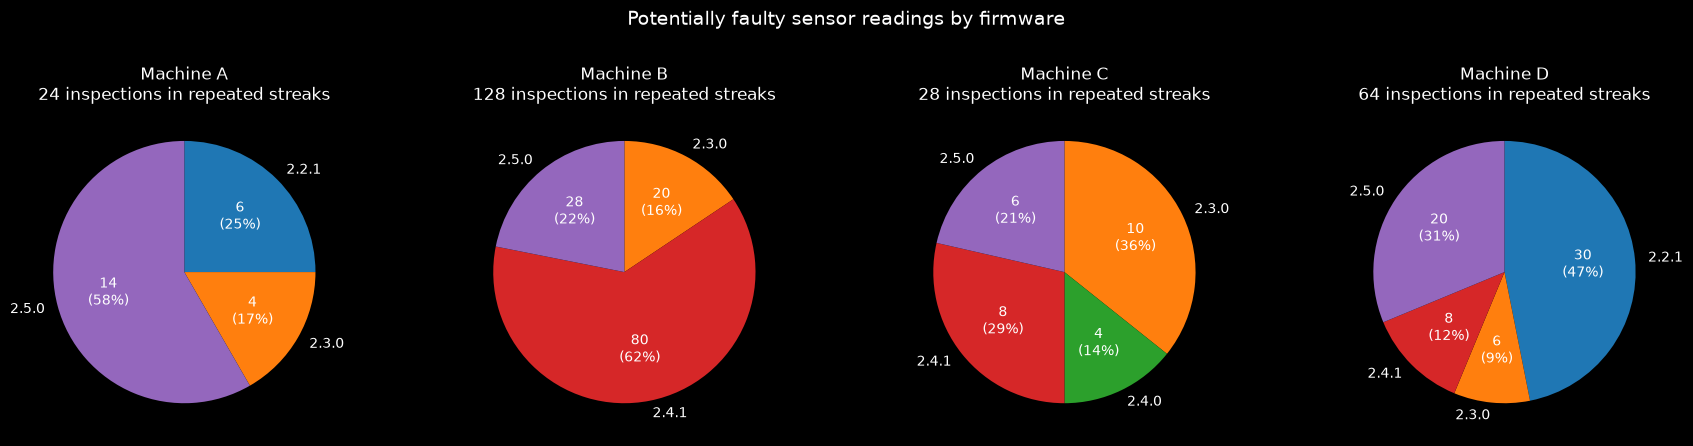

In [201]:
streaks = (
    pd.concat(potential_fault_sensor_by_batch_id, names=["machine", "same_result_batch_id"])
    .reset_index()
)

# Look up the firmware at the start of each streak
streaks["sensor_fw"] = df.loc[streaks["start_index"], "sensor_fw"].values

# Inspections inside repeated streaks, per machine and firmware
fw_counts = streaks.groupby(["machine", "sensor_fw"])["times_appeared"].sum()

# Same color for the same firmware in every pie
all_fw = sorted(streaks["sensor_fw"].unique())
fw_color = dict(zip(all_fw, plt.cm.tab10.colors))

machines = fw_counts.index.get_level_values("machine").unique()
fig, axes = plt.subplots(1, len(machines), figsize=(4.5 * len(machines), 4.5))

for ax, machine in zip(axes, machines):
    counts = fw_counts.loc[machine]
    ax.pie(
        counts,
        labels=counts.index,
        colors=[fw_color[f] for f in counts.index],
        autopct=lambda pct, total=counts.sum(): f"{round(pct * total / 100)}\n({pct:.0f}%)",
        startangle=90,
        counterclock=False,
    )
    ax.set_title(f"Machine {machine}\n{counts.sum()} inspections in repeated streaks")

fig.suptitle("Potentially faulty sensor readings by firmware", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

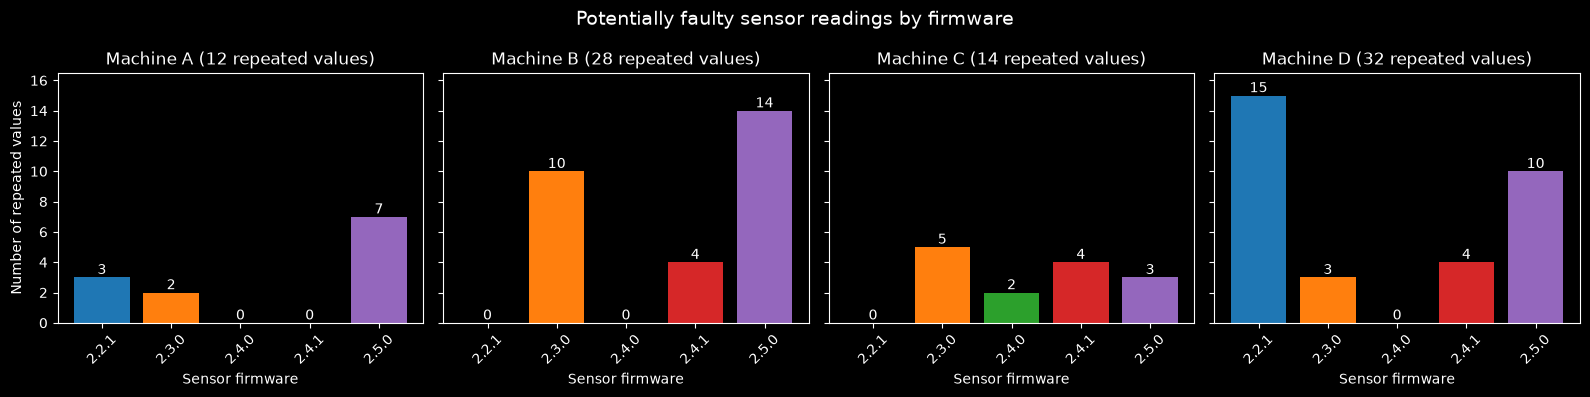

In [202]:
streaks = (
    pd.concat(potential_fault_sensor_by_batch_id, names=["machine", "same_result_batch_id"])
    .reset_index()
)
streaks["sensor_fw"] = df.loc[streaks["start_index"], "sensor_fw"].values

# Rows = firmware, columns = machine, values = number of repeated-value streaks
repeats = streaks.pivot_table(index="sensor_fw", columns="machine",
                              values="times_appeared", aggfunc="size", fill_value=0)

fw_color = dict(zip(repeats.index, plt.cm.tab10.colors))
machines = repeats.columns

fig, axes = plt.subplots(1, len(machines), figsize=(4 * len(machines), 4), sharey=True)

for ax, machine in zip(axes, machines):
    counts = repeats[machine]
    bars = ax.bar(counts.index, counts.values, color=[fw_color[f] for f in counts.index])
    ax.bar_label(bars)
    ax.margins(y=0.1)
    ax.set_title(f"Machine {machine} ({counts.sum()} repeated values)")
    ax.set_xlabel("Sensor firmware")
    ax.tick_params(axis="x", rotation=45)

axes[0].set_ylabel("Number of repeated values")
fig.suptitle("Potentially faulty sensor readings by firmware", fontsize=14)
plt.tight_layout()
plt.show()

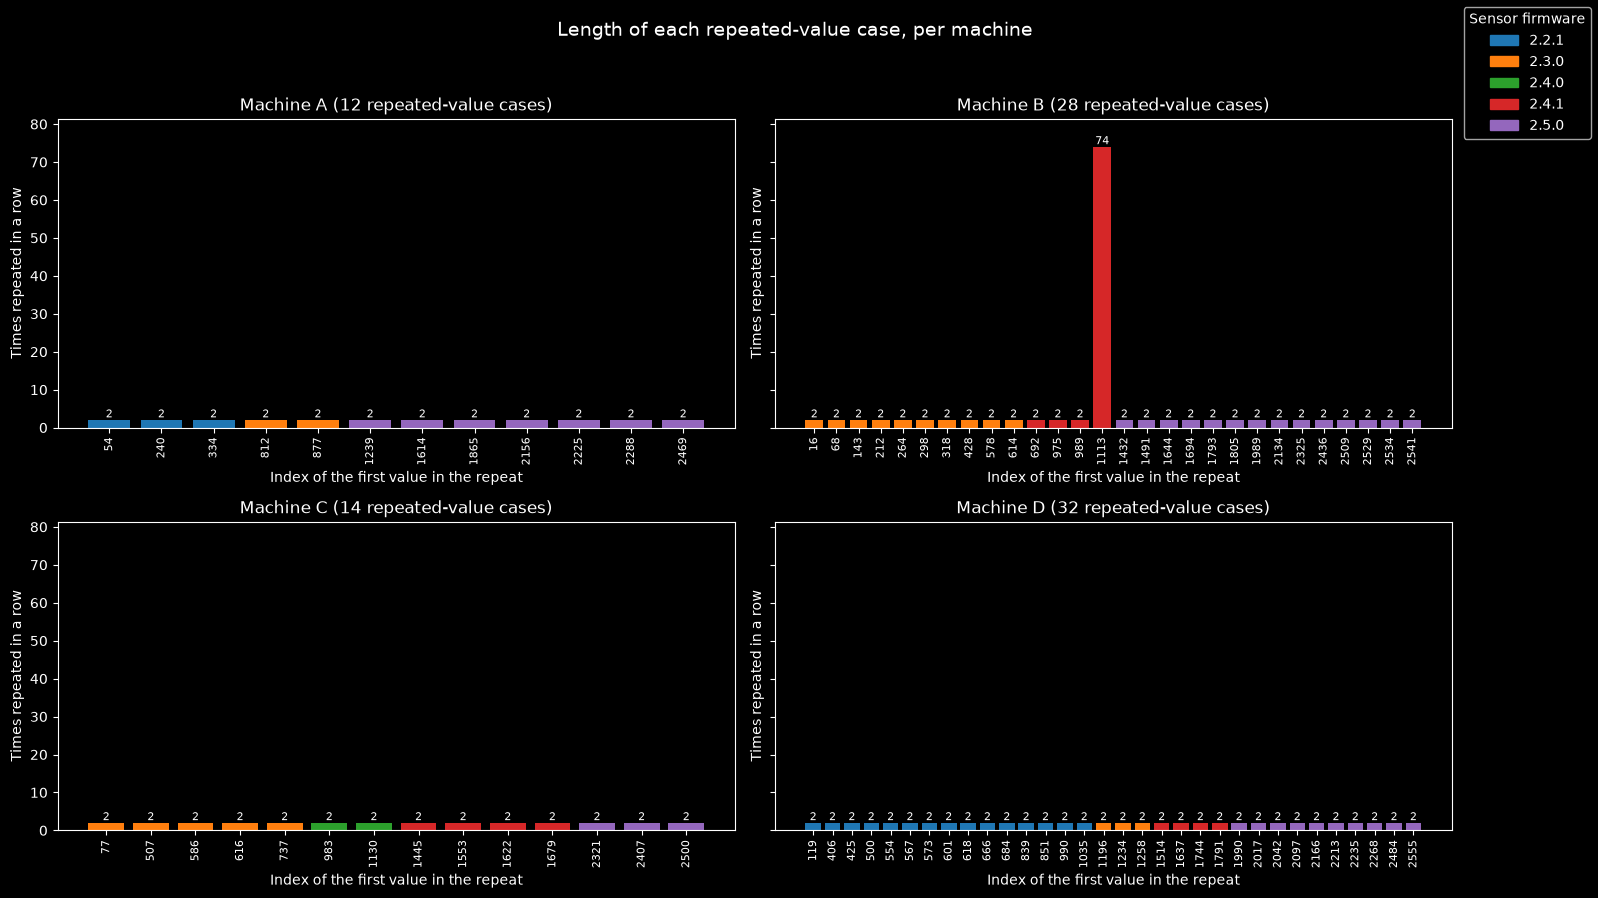

In [203]:
from matplotlib.patches import Patch

streaks = (
    pd.concat(potential_fault_sensor_by_batch_id, names=["machine", "same_result_batch_id"])
    .reset_index()
)
streaks["sensor_fw"] = df.loc[streaks["start_index"], "sensor_fw"].values

all_fw = sorted(streaks["sensor_fw"].unique())
fw_color = dict(zip(all_fw, plt.cm.tab10.colors))
machines = sorted(streaks["machine"].unique())

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)

for ax, machine in zip(axes.flat, machines):
    d = streaks[streaks["machine"] == machine].reset_index(drop=True)
    x = np.arange(len(d))

    bars = ax.bar(x, d["times_appeared"], color=d["sensor_fw"].map(fw_color))
    ax.bar_label(bars, labels=d["times_appeared"], fontsize=8)
    ax.set_xticks(x, d["start_index"], rotation=90, fontsize=8)  # index of the first value
    ax.margins(y=0.1)

    ax.set_title(f"Machine {machine} ({len(d)} repeated-value cases)")
    ax.set_xlabel("Index of the first value in the repeat")
    ax.set_ylabel("Times repeated in a row")

fig.legend(handles=[Patch(color=fw_color[f], label=f) for f in all_fw],
           title="Sensor firmware", loc="upper right")
fig.suptitle("Length of each repeated-value case, per machine", fontsize=14)
plt.tight_layout(rect=[0, 0, 0.92, 0.95])
plt.show()

In [204]:
def stats_table(df):
    """Per machine and firmware: batches, mean, variance and rate of defective items."""
    d = df[df["defective"] >= 0].copy()  # -1 = missing, would distort mean/var
    d["machine"] = d["machine"].str.strip().str.upper()  # otherwise ' a' is its own group
    keys = ["machine", "sensor_fw"]
    g = d.groupby(keys)
    t = g.agg(batches=("defective", "size"),
              mean=("defective", "mean"),
              var=("defective", "var"),
              inspected=("inspected", "sum"),
              defective=("defective", "sum"))
    t["rate"] = t["defective"] / t["inspected"]
    # Variance expected if defective ~ Binom(inspected, rate); batch sizes differ, so total variance
    p = g["defective"].transform("sum") / g["inspected"].transform("sum")
    d["_within"] = d["inspected"] * p * (1 - p)
    d["_np"] = d["inspected"] * p
    t["expected_var"] = d.groupby(keys)["_within"].mean() + d.groupby(keys)["_np"].var()
    return t[["batches", "mean", "var", "expected_var", "rate"]]

In [205]:
def firmware_ratios(df):
    """Each (machine, firmware): its defect rate / median rate of the OTHER firmware versions on that machine."""
    d = df[df["defective"] >= 0].copy()
    d["machine"] = d["machine"].str.strip().str.upper()
    rates = (d.groupby(["machine", "sensor_fw"])[["defective", "inspected"]].sum()
             .assign(rate=lambda t: t["defective"] / t["inspected"]))
    rows = []
    for (m, fw), r in rates.iterrows():
        others = rates.loc[m].drop(index=fw)["rate"]
        if len(others) == 0:
            continue  # nothing to compare with on this machine
        rows.append({"machine": m, "sensor_fw": fw, "rate": r["rate"],
                     "others_rate": others.median(), "ratio": r["rate"] / others.median()})
    return pd.DataFrame(rows)


def detect_scaled_firmware(df, tol=0.25, max_factor=10):
    """{firmware: k} for firmware versions whose rate is about k times the others (k >= 2) and
    whose every recorded value is divisible by k."""
    ratios = firmware_ratios(df)
    d = df[df["defective"] >= 0]
    scaled = {}
    for fw, g in ratios.groupby("sensor_fw"):
        ratio = g["ratio"].median()  # over the machines that use this firmware
        k = int(round(ratio))
        if not 2 <= k <= max_factor or abs(ratio - k) > tol:
            continue
        if (d.loc[d["sensor_fw"] == fw, "defective"] % k == 0).all():
            scaled[fw] = k
    return scaled


def scale_firmware_defective_output(df):
    df = df.copy()
    for fw, k in detect_scaled_firmware(df).items():
        print(f"scaling {fw} with {k}")
        rows = (df["sensor_fw"] == fw) & (df["defective"] >= 0)
        df.loc[rows, "defective"] //= k
    return df

In [206]:
scale_df = scale_firmware_defective_output(experimental_logs[1])

stats_table(scale_df)

scaling 2.4.0 with 2


batches       mean        var  expected_var      rate
machine sensor_fw                                                       
A       2.2.1           99  32.383838  88.728716     87.632389  0.066347
        2.3.0          153  32.941176  89.647833     92.895795  0.065209
        2.4.1           29  30.172414  94.647783     86.850115  0.063122
        2.5.0          360  33.650000  92.868802     90.319236  0.066359
B       2.3.0          208  21.144231  44.983928     42.416964  0.042693
        2.4.1          150  21.133333  27.498881     42.975132  0.042451
        2.5.0          321  21.177570  42.821495     42.919529  0.042827
C       2.3.0          255  29.819608  71.274417     76.219571  0.059989
        2.4.0           82  29.890244  76.642126     83.568781  0.059903
        2.4.1          265  29.328302  71.933476     72.954945  0.060109
        2.5.0          126  30.873016  71.231746     70.113731  0.059774
D       2.2.1          260  16.434615  31.876017     29.912847  0.032690
        2.3.0           44  18.204545  34.213002     31.406124  0.035695
        2.4.1          131  16.702290  38.749149     32.136543  0.034626
        2.5.0          179  17.379888  32.180717     32.638350  0.034493

In [207]:
stats_table(clean)

batches       mean        var  expected_var      rate
machine sensor_fw                                                       
A       2.3.0          479  29.450939  72.603760     72.826765  0.059555
        2.4.1          145  30.358621  73.870498     74.260673  0.059203
        2.5.0          102  29.460784  90.488546     76.359234  0.058828
B       2.3.0          214  24.705607  60.809640     56.516097  0.049834
        2.4.1           13  24.076923  32.410256     53.019840  0.048640
        2.5.0          451  25.000000  49.942222     56.513491  0.049748
C       2.2.1          326  27.797546  64.112732     69.130170  0.055372
        2.3.0           59  27.389831  69.310929     60.768407  0.055308
        2.4.1          277  27.191336  63.684272     64.827090  0.054858
        2.5.0           51  28.450980  80.212549     75.057157  0.056266
D       2.3.0          115  12.226087  18.422121     20.355159  0.024804
        2.4.1          497  12.134809  19.241871     19.290821  0.023967
        2.5.0          106  12.245283  19.844025     20.137195  0.024664

In [208]:
def repeat_thresholds(df, alpha=0.01):
    rows = []
    for (machine, fw), group in df.groupby(["machine", "sensor_fw"]):
        # 1. Defect rate and typical batch size of this machine + firmware
        rate = group["defective"].sum() / group["inspected"].sum()
        batch_size = round(group["inspected"].mean())

        # 2. Chance that two batches get the same number of defective items by luck
        counts = np.arange(batch_size + 1)
        p_same = (stats.binom.pmf(counts, batch_size, rate) ** 2).sum()

        # 3. Smallest run length whose expected number of lucky runs is <= alpha
        threshold = 2
        while len(group) * p_same ** (threshold - 1) > alpha:
            threshold += 1

        rows.append({"machine": machine, "sensor_fw": fw, "batches": len(group),
                     "rate": rate, "p_same": p_same, "threshold": threshold})

    return pd.DataFrame(rows).set_index(["machine", "sensor_fw"])


def remove_stuck_runs(df, thresholds):
    """Keep the first value of a run that is at least `threshold` long, drop its repeats."""
    df = df.sort_values(["machine", "log_line"])
    run = (df["defective"] != df.groupby("machine")["defective"].shift()).cumsum()
    run_len = df.groupby(run)["defective"].transform("size")
    is_repeat = df.groupby(run).cumcount() > 0
    limit = df.join(thresholds["threshold"], on=["machine", "sensor_fw"])["threshold"]
    return df[~(is_repeat & (run_len >= limit))].sort_index()

In [209]:
# Calculate chances of thresholds of repeated cases per firmware, for each machine
# Pick a threshold that has <= 1% chance of False Positive faulty sensor (the chances that the sensor is falsely detected as Faulted)
thresholds = repeat_thresholds(df)
display(thresholds)
df = remove_stuck_runs(df, thresholds)

batches      rate    p_same  threshold
machine sensor_fw                                        
A       2.2.1           99  0.066347  0.051375          5
        2.3.0          133  0.065379  0.050697          5
        2.4.1           29  0.063122  0.053134          4
        2.5.0          360  0.066359  0.050396          5
B       2.3.0          185  0.042645  0.062520          5
        2.4.1          150  0.042451  0.062847          5
        2.5.0          321  0.042827  0.062835          5
C       2.3.0          234  0.059986  0.053313          5
        2.4.0           82  0.119806  0.038905          4
        2.4.1          265  0.060109  0.053806          5
        2.5.0          126  0.059774  0.052459          5
D       2.2.1          242  0.032663  0.071133          5
        2.3.0           44  0.035695  0.067522          5
        2.4.1          131  0.034626  0.070500          5
        2.5.0          179  0.034493  0.069064          5

In [210]:
df = df[["batch_id", "machine", "inspected", "defective"]]

In [211]:
print({i: len(c) for i, c in logs.items()})
cleaned = {i: hw1.clean_log(logs[i]) for i in logs}
{i: len(c) for i, c in cleaned.items()}

{1: 2686, 2: 3186, 3: 2799}


{1: 2507, 2: 2931, 3: 2634}

In [219]:
clean_logs_after_method = hw1.clean_log(clean)
if clean.count()['batch_id'] != clean_logs_after_method.count()['batch_id']:
    print("Something is wrong with the cleaning method")

print(clean_logs_after_method.head())

   batch_id machine  inspected  defective
0    100003       C        539         31
1    100004       D        449          6
2    100006       B        598         36
3    100007       B        572         28
4    100009       A        441         23


#### 5.B (6 points)
Complete `defect_rates(df)` that returns a dict `{machine: rate}` with the estimated defect rate of each machine:
(total defective products) / (total inspected products) over the machine's usable batches.

For `factory_log_clean.csv` you should get approximately
`{'A': 0.0593801, 'B': 0.0497535, 'C': 0.0552334, 'D': 0.0241998}`.

In [213]:
rates_by_machine = {}

groups = clean_logs_after_method.groupby('machine')
table_per_machine = {}

for machine_name, machine_rows in groups:
    table_per_machine[machine_name] = machine_rows
    total_inspected = machine_rows['inspected'].sum()
    total_defective = machine_rows['defective'].sum()
    machine_rate = total_defective / total_inspected
    rates_by_machine[machine_name] = machine_rate

print(rates_by_machine)
type(rates_by_machine)

{'A': np.float64(0.05938008887416853), 'B': np.float64(0.04975351738940714), 'C': np.float64(0.05523342379242728), 'D': np.float64(0.024199759526144605)}


dict

In [214]:
hw1.defect_rates(clean)

{'A': np.float64(0.05938008887416853),
 'B': np.float64(0.04975351738940714),
 'C': np.float64(0.05523342379242728),
 'D': np.float64(0.024199759526144605)}

#### 5.C (6 points)
For a machine with $N$ inspected products and $D$ defective ones (over its usable batches), the right-sided p-value of the claim
"the defect rate is $p_0$" is $P(X \ge D)$ for $X \sim Binom(N, p_0)$.

Complete `log10_pvalue(df, machine, p0)` that returns $\log_{10}$ of this p-value.
It must be accurate (relative error below $10^{-6}$) **even when the p-value is far below $10^{-300}$**.

For `factory_log_clean.csv`: `log10_pvalue(clean, 'B', 0.03)` $\approx -829.7209$ and
`log10_pvalue(clean, 'C', 0.05)` $\approx -44.7035$.

In [215]:
def prototype_5_c(machine='B', p0=0.03):
    machine_rows = clean_logs_after_method.groupby('machine').get_group(machine)
    total_inspected = machine_rows['inspected'].sum()
    total_defective = machine_rows['defective'].sum()
    X = stats.binom(total_inspected, p0)
    possible_counts = np.arange(total_defective, total_inspected + 1)
    log_probs = X.logpmf(possible_counts)
    log_pvalue = logsumexp(log_probs) / np.log(10)
    print(machine, log_pvalue)

In [221]:
prototype_5_c()
prototype_5_c('C', 0.05)

B -829.720946778514
C -44.70345327744749


In [228]:
hw1.log10_pvalue(clean, 'B', 0.03), hw1.log10_pvalue(clean, 'C', 0.05)

(np.float64(-829.720946778514), np.float64(-44.70345327744749))

#### 5.D (6 points)
We want to send products of a machine to a lab that needs at least $r$ defective products.
Complete `items_needed(df, machine, r, q)` that returns the smallest number of products $n$ we must take so that
$P(\text{at least } r \text{ of them are defective}) \ge q$, assuming that every product is defective independently with probability
equal to the machine's estimated defect rate (5.B).

For `factory_log_clean.csv`: `items_needed(clean, 'A', 10, 0.95)` $= 262$.

In [229]:
machine_rates = hw1.defect_rates(clean)
# print(machine_rates)
r = 10
threshold = 0.95
machine = 'A'
rate = machine_rates[machine]
p_defect = 0
X = stats.nbinom(r, rate, loc=r)

low = 0
high = r
while X.cdf(high) < threshold:
    high = high * 2

while low < high:
    mid = low + ((high - low) // 2)

    p_defect = X.cdf(mid)

    if p_defect >= threshold:
        high = mid
    else:
        low = mid + 1

print(low)

262


In [232]:
hw1.items_needed(clean, 'A', 10, 0.95)

262

---
## Self-check (run before submitting)

This cell calls every function once and checks that it runs and returns the right **type**.
It does not check that your answers are correct.

In [248]:
import importlib, time, traceback

importlib.reload(hw1)


def _num(x):  return isinstance(x, (int, float, np.integer, np.floating)) and not isinstance(x, bool)


def _int(x):  return isinstance(x, (int, np.integer)) and not isinstance(x, bool)


def _pmf(x):  return isinstance(x, np.ndarray) and x.ndim == 2 and x.shape[0] == 2


def _tup(n, f): return lambda x: isinstance(x, tuple) and len(x) == n and all(f(v) for v in x)


def _df(x):   return isinstance(x, pd.DataFrame) and {'batch_id', 'machine', 'inspected', 'defective'} <= set(x.columns)


def _rates(x): return isinstance(x, dict) and set(map(str, x)) == {'A', 'B', 'C', 'D'} and all(
    _num(v) for v in x.values())


_log = pd.read_csv('factory_log_1.csv')
_P = np.array([[0, 3, -1], [0.2, 0.5, 0.3]])
checks = [
    ('binom_pvalue', lambda: hw1.binom_pvalue(k=5, n=20, p0=0.1), _num),
    ('critical_k', lambda: hw1.critical_k(n=30, p0=0.3, alpha=0.05), _int),
    ('power', lambda: hw1.power(n=30, p0=0.3, p1=0.5, alpha=0.05), _num),
    ('power_drops', lambda: hw1.power_drops(p0=0.3, p1=0.5, alpha=0.05, n_max=40),
     lambda x: isinstance(x, np.ndarray) and x.ndim == 1),
    ('min_sample_size', lambda: hw1.min_sample_size(p0=0.3, p1=0.5, alpha=0.05, target=0.7), _int),
    ('shots_pmf (int)', lambda: hw1.shots_pmf(t=7, r=2, p=0.3), _num),
    ('shots_pmf (array)', lambda: hw1.shots_pmf(t=np.arange(10), r=2, p=0.3),
     lambda x: isinstance(x, np.ndarray) and x.shape == (10,)),
    ('duel_probs', lambda: hw1.duel_probs(pA=0.2, rA=3, pB=0.3, rB=4), _tup(3, _num)),
    ('duel_expected_length', lambda: hw1.duel_expected_length(pA=0.2, rA=3, pB=0.3, rB=4), _num),
    ('conv_pmf', lambda: hw1.conv_pmf(P=_P, Q=_P), _pmf),
    ('nfold_pmf', lambda: hw1.nfold_pmf(P=_P, n=4), _pmf),
    ('cc_cdf', lambda: hw1.cc_cdf(N=10, t=30), _num),
    ('cc_partial_quantile', lambda: hw1.cc_partial_quantile(N=20, m=15, q=0.9), _int),
    ('clean_log', lambda: hw1.clean_log(df=_log.copy()), _df),
    ('defect_rates', lambda: hw1.defect_rates(df=_log.copy()), _rates),
    ('log10_pvalue', lambda: hw1.log10_pvalue(df=_log.copy(), machine='A', p0=0.03), _num),
    ('items_needed', lambda: hw1.items_needed(df=_log.copy(), machine='A', r=5, q=0.9), _int),
]
n_ok = 0
for name, call, ok in checks:
    t0 = time.time()
    try:
        out = call()
        good = ok(out)
        msg = 'OK  ' if good else 'BAD TYPE: got %s' % type(out).__name__
        n_ok += good
    except Exception as e:
        msg = 'ERROR: %s: %s' % (type(e).__name__, e)
    print('%-22s %-50s %.2fs' % (name, msg, time.time() - t0))
print('\n%d / %d functions returned the expected type' % (n_ok, len(checks)))

binom_pvalue           OK                                                 0.00s
critical_k             OK                                                 0.00s
power                  OK                                                 0.00s
power_drops            OK                                                 0.00s
min_sample_size        OK                                                 0.00s
shots_pmf (int)        OK                                                 0.00s
shots_pmf (array)      OK                                                 0.00s
duel_probs             OK                                                 0.01s
duel_expected_length   OK                                                 0.02s
conv_pmf               OK                                                 0.00s
nfold_pmf              BAD TYPE: got NoneType                             0.00s
cc_cdf                 BAD TYPE: got NoneType                             0.00s
cc_partial_quantile    BAD TYPE: got Non